In [1]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="gpt-oss:120b-cloud")
print('Model is ready')


c:\Users\ak60492\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model is ready


In [2]:
# STEP 1: Define your state
from typing import TypedDict
from langchain_core.messages import AnyMessage
from langgraph.graph.message import Annotated, add_messages

class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

print('State is defined')

State is defined


In [3]:
# STEP 2: Define your nodes

def assistant_node(state: AgentState) -> dict:
    """One graph noce: call the LLM using current messages"""
    response = model.invoke(state['messages'])
    return {"messages": [response]}
print('Nodes are defined')

Nodes are defined


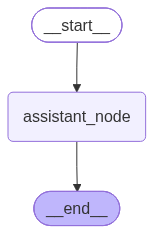

In [4]:
from langgraph.graph import StateGraph, START, END

graph_builder = StateGraph(AgentState)

# Node registration
graph_builder.add_node("assistant_node", assistant_node)

# Add edges to nodes
graph_builder.add_edge(START, "assistant_node")
graph_builder.add_edge("assistant_node", END)

graph = graph_builder.compile()
graph

In [5]:
response = graph.invoke({"messages": [{"role": "user", "content": "I am Anand"}]})
response

{'messages': [HumanMessage(content='I am Anand', additional_kwargs={}, response_metadata={}, id='45eb3eb7-b813-4cec-a2a1-1cdf854d863e'),
  AIMessage(content='Nice to meet you, Anand! How can I assist you today?', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-10-27T04:31:36.301618662Z', 'done': True, 'done_reason': 'stop', 'total_duration': 297806697, 'load_duration': None, 'prompt_eval_count': 70, 'prompt_eval_duration': None, 'eval_count': 59, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a17ba0-c14d-70b0-86e0-204056d7e21b-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 70, 'output_tokens': 59, 'total_tokens': 129})]}

In [6]:
response = graph.invoke({"messages": [{"role": "user", "content": "What is my name?"}]})
response

{'messages': [HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='8682663c-15ea-4fb0-bd03-bdcedb4bff57'),
  AIMessage(content='I don’t have any information about your name. If you’d like to share it, I’d be happy to address you by name! Otherwise, feel free to let me know how I can help you.', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-10-27T04:32:33.482534399Z', 'done': True, 'done_reason': 'stop', 'total_duration': 489707630, 'load_duration': None, 'prompt_eval_count': 72, 'prompt_eval_duration': None, 'eval_count': 100, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a17ba1-a0fc-7662-90f4-e4d4f034b62f-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 100, 'total_tokens': 172})]}

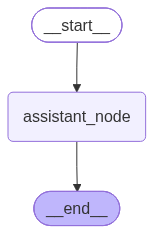

In [7]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver

short_term_memory = MemorySaver()
graph_builder = StateGraph(AgentState)

# Node registration
graph_builder.add_node("assistant_node", assistant_node)

# Add edges to nodes
graph_builder.add_edge(START, "assistant_node")
graph_builder.add_edge("assistant_node", END)

graph = graph_builder.compile(checkpointer=short_term_memory)
graph

In [9]:
config = {"configurable": {"thread_id": "Tourist_places_in_India"}}
response = graph.invoke({"messages": [{"role": "user", "content": "I am Anand"}]}, config)
response

{'messages': [HumanMessage(content='I am Anand', additional_kwargs={}, response_metadata={}, id='b0125764-d019-40f9-a5a2-47c64f0a3799'),
  AIMessage(content='Nice to meet you, Anand! 👋 How can I help you today? Whether you have a question, need some advice, or just want to chat, I’m here for you.', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-10-27T04:37:01.881000524Z', 'done': True, 'done_reason': 'stop', 'total_duration': 503074799, 'load_duration': None, 'prompt_eval_count': 70, 'prompt_eval_duration': None, 'eval_count': 94, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a17ba5-b5c0-7562-b326-fb2d0a90f279-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 70, 'output_tokens': 94, 'total_tokens': 164})]}

In [10]:
response = graph.invoke({"messages": [{"role": "user", "content": "What is my name?"}]}, config)
response

{'messages': [HumanMessage(content='I am Anand', additional_kwargs={}, response_metadata={}, id='b0125764-d019-40f9-a5a2-47c64f0a3799'),
  AIMessage(content='Nice to meet you, Anand! 👋 How can I help you today? Whether you have a question, need some advice, or just want to chat, I’m here for you.', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-10-27T04:37:01.881000524Z', 'done': True, 'done_reason': 'stop', 'total_duration': 503074799, 'load_duration': None, 'prompt_eval_count': 70, 'prompt_eval_duration': None, 'eval_count': 94, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a17ba5-b5c0-7562-b326-fb2d0a90f279-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 70, 'output_tokens': 94, 'total_tokens': 164}),
  HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='359bc764-3479-46df-8f9c-b1a5759de240'),
  AIMessage(content='Y

In [11]:
config = {"configurable": {"thread_id": "Global_warming"}}
response = graph.invoke({"messages": [{"role": "user", "content": "What is my name?"}]}, config)
response

{'messages': [HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='b474d90b-ffa1-4fd1-8a1c-f2c3d6720efa'),
  AIMessage(content='I don’t have any information about your name. If you’d like, you can tell me what you’d like to be called, and I’ll be happy to use it!', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-10-27T04:40:34.097355589Z', 'done': True, 'done_reason': 'stop', 'total_duration': 642724468, 'load_duration': None, 'prompt_eval_count': 72, 'prompt_eval_duration': None, 'eval_count': 99, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a17ba8-f577-7552-b41f-c5f67dcf88a0-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 99, 'total_tokens': 171})]}

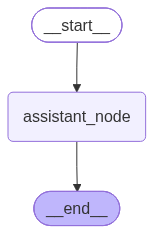

In [12]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.sqlite import SqliteSaver
import sqlite3

db_path = "zenapp.db"
sqllite_connection = sqlite3.connect(db_path, check_same_thread=False)
short_term_memory = SqliteSaver(sqllite_connection)
graph_builder = StateGraph(AgentState)

# Node registration
graph_builder.add_node("assistant_node", assistant_node)

# Add edges to nodes
graph_builder.add_edge(START, "assistant_node")
graph_builder.add_edge("assistant_node", END)

graph = graph_builder.compile(checkpointer=short_term_memory)
graph

In [13]:
config = {"configurable": {"thread_id": "Tourist_places_in_India"}}
response = graph.invoke({"messages": [{"role": "user", "content": "I am Anand"}]}, config)
response

{'messages': [HumanMessage(content='I am Anand', additional_kwargs={}, response_metadata={}, id='f07c2b9d-2c14-4016-b85f-9e6d8ffb63e1'),
  AIMessage(content='Nice to meet you, Anand! 👋 How can I help you today? Whether you have a question, need some advice, or just want to chat, I’m here. Feel free to let me know what’s on your mind.', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-10-27T04:47:24.067310345Z', 'done': True, 'done_reason': 'stop', 'total_duration': 435996375, 'load_duration': None, 'prompt_eval_count': 70, 'prompt_eval_duration': None, 'eval_count': 100, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a17baf-378e-7bd3-82d2-5a8583c04536-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 70, 'output_tokens': 100, 'total_tokens': 170})]}

In [14]:
response = graph.invoke({"messages": [{"role": "user", "content": "What is my name?"}]}, config)
response

{'messages': [HumanMessage(content='I am Anand', additional_kwargs={}, response_metadata={}, id='f07c2b9d-2c14-4016-b85f-9e6d8ffb63e1'),
  AIMessage(content='Nice to meet you, Anand! 👋 How can I help you today? Whether you have a question, need some advice, or just want to chat, I’m here. Feel free to let me know what’s on your mind.', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-10-27T04:47:24.067310345Z', 'done': True, 'done_reason': 'stop', 'total_duration': 435996375, 'load_duration': None, 'prompt_eval_count': 70, 'prompt_eval_duration': None, 'eval_count': 100, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a17baf-378e-7bd3-82d2-5a8583c04536-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 70, 'output_tokens': 100, 'total_tokens': 170}),
  HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='90c52bd4-37e2-4021-9e4

In [18]:
# Tools definition
from langchain_community.tools import tool

@tool
def get_weather(city: str) -> str:
    """Get weather for a city"""
    return f"The weather in the city {city} is Sunny"

@tool
def get_stock_price(stock: str) -> str:
    """Returns the stock price for a given stock"""
    return f"The stock price of {stock} is 25.50"

get_weather
get_stock_price
print('Tools are ready')

Tools are ready


In [26]:
from langgraph.config import get_store, get_config

@tool
def save_memory(fact: str) -> str:
    """Save an important fact about the user for future conversations
    (e.g. their name, workplace, or a stated preference)."""
    store = get_store()
    user_id = get_config()["configurable"]["user_id"]
    store.put(("memories", user_id), fact[:40], {"text": fact})
    return f"Saved: {fact}"

@tool
def recall_memories(query: str) -> str:
    """Search saved facts about the user relevant to the query.
    ALWAYS call this before claiming you don't know something about the user."""
    store = get_store()
    user_id = get_config()["configurable"]["user_id"]
    results = store.search(("memories", user_id), query=query, limit=5)
    if not results:
        return "No relevant memories found."
    return "\n".join(f"- {r.value['text']}" for r in results)

print("Memory tools ready: save_memory, recall_memories")


Memory tools ready: save_memory, recall_memories


In [27]:
# Example - Long term memory
# Creating an agent
from langchain.agents import create_agent
from langgraph.store.memory import InMemoryStore

long_term_memory = InMemoryStore()

agent = create_agent(
    model=model,
    tools=[get_weather, get_stock_price, save_memory, recall_memories],
    system_prompt=(
        "You are a helpful assistant with long-term memory. "
        "When the user shares a personal fact, call save_memory, then briefly confirm. "
        "When asked what you know about the user, ALWAYS call recall_memories first. "
        "Your final answer MUST be based only on the tool output returned -- restate those facts plainly. "
        "Never say you don't know something if the tool result contains it."
    ),
    store=long_term_memory
)
print('AI agent is ready')

AI agent is ready


In [29]:
config = {"configurable": {"thread_id": "Tourist_places_in_India", "user_id": "anand"}}
response = agent.invoke({"messages": [{"role": "user", "content": "I am Anand"}]}, config)
response

{'messages': [HumanMessage(content='I am Anand', additional_kwargs={}, response_metadata={}, id='ac82a433-1894-4081-ac75-5b1ad82b417f'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-10-27T05:01:08.941888539Z', 'done': True, 'done_reason': 'stop', 'total_duration': 444594633, 'load_duration': None, 'prompt_eval_count': 311, 'prompt_eval_duration': None, 'eval_count': 54, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a17bbb-caa0-7033-bb92-1b644101a19b-0', tool_calls=[{'name': 'save_memory', 'args': {'fact': "User's name is Anand"}, 'id': 'a6b123fa-2b1f-4728-88b1-3f60213541b3', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 311, 'output_tokens': 54, 'total_tokens': 365}),
  ToolMessage(content="Saved: User's name is Anand", name='save_memory', id='e8dd3804-f097-4ae7-9c27-b2a36e6bd584', tool_call_id='a6b123fa-2b1f-4728-88b1-3f60

In [30]:
response = agent.invoke({"messages": [{"role": "user", "content": "What is my name?"}]}, config)
response

{'messages': [HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='33d7f61f-13db-4416-a59a-5515274f0209'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-10-27T05:01:35.737642322Z', 'done': True, 'done_reason': 'stop', 'total_duration': 506113164, 'load_duration': None, 'prompt_eval_count': 313, 'prompt_eval_duration': None, 'eval_count': 82, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a17bbc-367b-76e0-8f39-a10a8da3c1e6-0', tool_calls=[{'name': 'recall_memories', 'args': {'query': 'name'}, 'id': '7239307a-8fb9-4e6a-b69c-6b96751000c1', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 313, 'output_tokens': 82, 'total_tokens': 395}),
  ToolMessage(content="- User's name is Anand", name='recall_memories', id='23e6ad70-558e-45a7-b3f7-3b89c0527076', tool_call_id='7239307a-8fb9-4e6a-b69c-6b96751000

In [31]:
config_2 = {"configurable": {"thread_id": "Global_warming", "user_id": "anand"}}
response = agent.invoke({"messages": [{"role": "user", "content": "What is my name?"}]}, config_2)
response

{'messages': [HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='56be9bc6-5773-4ac9-8070-f3a4163324aa'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-10-27T05:02:58.774129317Z', 'done': True, 'done_reason': 'stop', 'total_duration': 456766993, 'load_duration': None, 'prompt_eval_count': 313, 'prompt_eval_duration': None, 'eval_count': 90, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a17bbd-7b1e-70b0-b8d5-7bf4a43f0be9-0', tool_calls=[{'name': 'recall_memories', 'args': {'query': 'name'}, 'id': 'cda0602c-d529-4987-bc44-131d7e07451d', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 313, 'output_tokens': 90, 'total_tokens': 403}),
  ToolMessage(content="- User's name is Anand", name='recall_memories', id='25cfdfe4-e85e-434e-8030-e245e33eb7e8', tool_call_id='cda0602c-d529-4987-bc44-131d7e0745

In [ ]:
config_3 = {"configurable": {"thread_id": "Tourist_places_in_India", "user_id": "tom"}}
response = agent.invoke({"messages": [{"role": "user", "content": "What is my name?"}]}, config_3)
response